# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

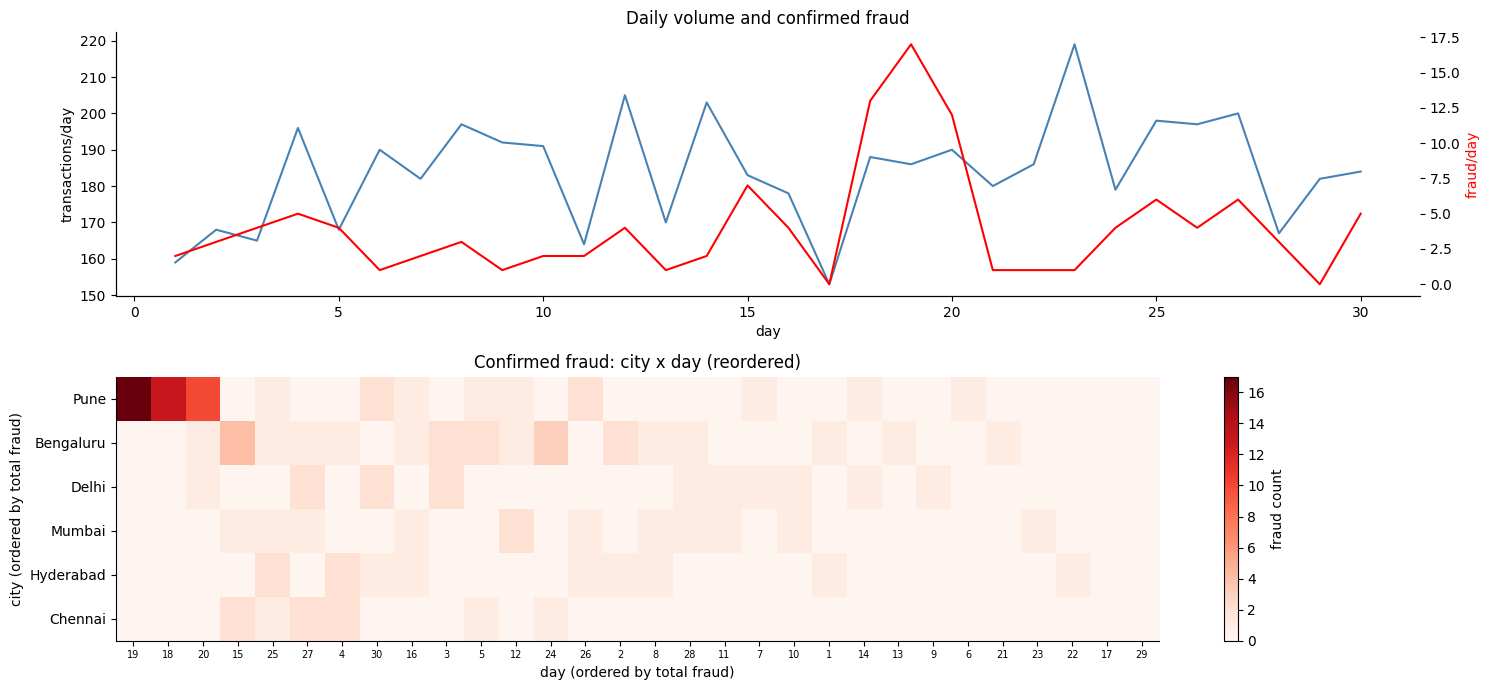

Top (city, day) fraud cells:
  Pune, day 19: 17
  Pune, day 18: 13
  Pune, day 20: 10
  Bengaluru, day 15: 4
  Bengaluru, day 24: 3
  Bengaluru, day 3: 2
  Pune, day 26: 2
  Bengaluru, day 2: 2


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily = tx.groupby("day").agg(n=("txn_id", "size"), fraud=("is_fraud", "sum"))
axes[0].plot(daily.index, daily.n, color="steelblue"); axes[0].set(ylabel="transactions/day", xlabel="day", title="Daily volume and confirmed fraud")
b = axes[0].twinx(); b.plot(daily.index, daily.fraud, color="red"); b.set_ylabel("fraud/day", color="red")

# TODO 2
heat = (tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="txn_id", aggfunc="count", fill_value=0)
          .reindex(columns=range(tx.day.min(), tx.day.max() + 1), fill_value=0))
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index, heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_yticks(range(len(heat.index))); axes[1].set_yticklabels(heat.index)
axes[1].set_xticks(range(len(heat.columns))); axes[1].set_xticklabels(heat.columns, fontsize=7)
axes[1].set(xlabel="day (ordered by total fraud)", ylabel="city (ordered by total fraud)", title="Confirmed fraud: city x day (reordered)")
plt.colorbar(im, ax=axes[1], label="fraud count")

plt.tight_layout(); plt.show()

# TODO 3
print("Top (city, day) fraud cells:")
for (c, d), v in heat.stack().sort_values(ascending=False).head(8).items(): print(f"  {c}, day {d}: {int(v)}")

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview showed a burst that no single alert reveals: Pune on days 18-20 holds 17 + 13 + 10 = 40 of the 120 confirmed frauds (a third), while every other city-day cell has at most 4. An alert list sorted by detector score shows individual transactions, not the concentration in space and time. The idea is the **reordered matrix / overview first** (Slides 38-39): reordering rows and columns by their totals pushes the hot cells to a corner.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

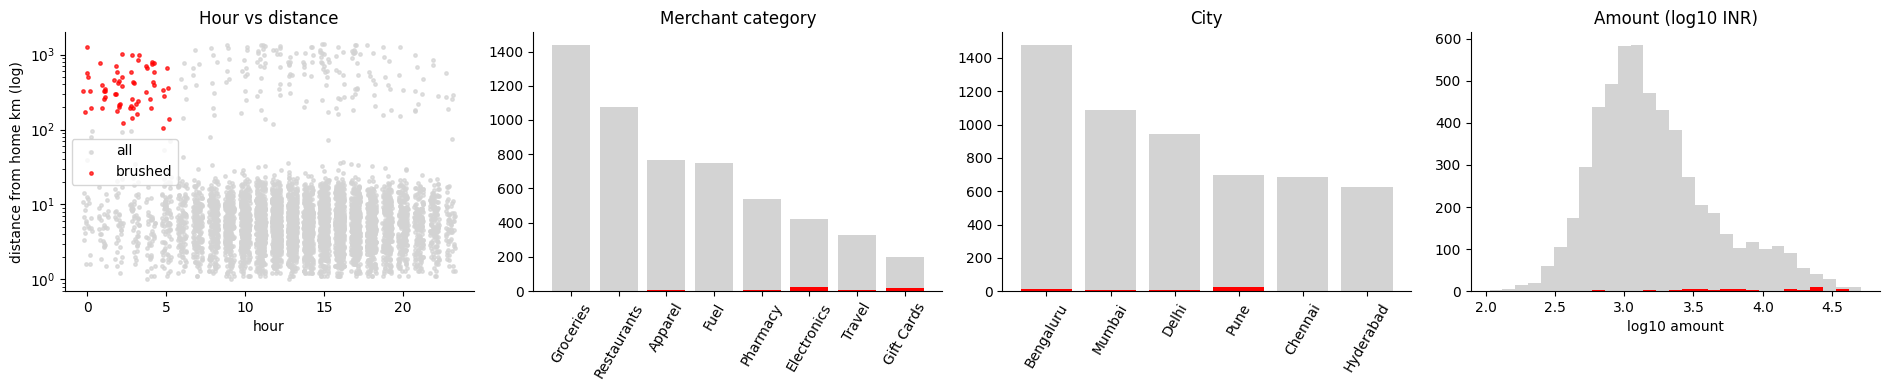

Brushed: 61 | fraud rate in brush 86.9% vs overall 2.2% | brush captures 44.2% of all fraud (53 of 120)


In [3]:
# TODO 1
brush = (tx.night) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
for m, c, l in [(~brush, "lightgrey", "all"), (brush, "red", "brushed")]:
    axes[0].scatter(tx.hour[m] + np.random.uniform(-.3, .3, m.sum()), tx.distance_from_home_km[m] + 1, s=6, c=c, label=l, alpha=.7)
axes[0].set_yscale("log"); axes[0].set(xlabel="hour", ylabel="distance from home km (log)", title="Hour vs distance"); axes[0].legend()
cat = tx.merchant_category.value_counts(); bc = tx[brush].merchant_category.value_counts().reindex(cat.index, fill_value=0)
axes[1].bar(cat.index, cat.values, color="lightgrey"); axes[1].bar(cat.index, bc.values, color="red"); axes[1].set_title("Merchant category"); axes[1].tick_params(axis="x", rotation=60)
cc = tx.city.value_counts(); bcc = tx[brush].city.value_counts().reindex(cc.index, fill_value=0)
axes[2].bar(cc.index, cc.values, color="lightgrey"); axes[2].bar(cc.index, bcc.values, color="red"); axes[2].set_title("City"); axes[2].tick_params(axis="x", rotation=60)
bins = np.linspace(np.log10(tx.amount_inr.min() + 1), np.log10(tx.amount_inr.max() + 1), 30)
axes[3].hist(np.log10(tx.amount_inr + 1), bins=bins, color="lightgrey"); axes[3].hist(np.log10(tx.amount_inr[brush] + 1), bins=bins, color="red")
axes[3].set(title="Amount (log10 INR)", xlabel="log10 amount")

plt.tight_layout(); plt.show()

# TODO 3
print(f"Brushed: {int(brush.sum())} | fraud rate in brush {tx.is_fraud[brush].mean():.1%} vs overall {tx.is_fraud.mean():.1%} | "
      f"brush captures {tx.is_fraud[brush].sum() / tx.is_fraud.sum():.1%} of all fraud ({int(tx.is_fraud[brush].sum())} of {int(tx.is_fraud.sum())})")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The brush (night and > 100 km from home) has a fraud rate of 86.9% against 2.2% overall, but it captures only 53 of 120 frauds, **44.2%**. Relying on the rule alone would miss more than half of the fraud. The linked views do not encode fraud directly, but they show how little of the space the brush covers: in the hour-vs-distance view the red points occupy only the night/far-from-home corner, and the fraud that is missed is mostly daytime (median hour 13) and still far from home (median about 144 km), so the 'night' condition is the weak part of the rule. The **city view** and the Task 1 heatmap point to where the rest is: 27 of the 67 missed frauds are in Pune, and by category Electronics and Gift Cards dominate.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
def run_filter():
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    return time.perf_counter() - t0
best_s = min(run_filter() for _ in range(5))

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = best_s / len(big) * 50_000_000
skip_pct = max(0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 6.4 ms -> 0.0064 us/row -> max 15,631,873 rows in 0.1 s
50M rows -> 0.32 s; must skip 68.7% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

A **reduce** technique is **sampling** or **pre-aggregation/binning** (Slides 5, 14): keep a random sample or aggregates (counts per city/hour/score bin) and filter those instead of 50M raw rows. What the analyst loses is the individual records: fraud is only 2.2% of transactions, so random sampling can drop the rare cases and aggregation hides outliers and single-transaction details (on this machine the 1M-row filter took about 7.4 ms, so 50M rows would take about 0.37 s and ~73% of the rows would have to be skipped to stay within 0.1 s).

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.057,0.950,0.107
1,0.10,1167,111,1056,9,0.095,0.925,0.172
2,0.15,786,110,676,10,0.140,0.917,0.243
3,0.20,596,106,490,14,0.178,0.883,0.296
4,0.25,471,105,366,15,0.223,0.875,0.355
5,0.30,401,104,297,16,0.259,0.867,0.399
6,0.35,355,104,251,16,0.293,0.867,0.438
7,0.40,319,104,215,16,0.326,0.867,0.474
8,0.45,283,104,179,16,0.367,0.867,0.516
9,0.50,260,101,159,19,0.388,0.842,0.532


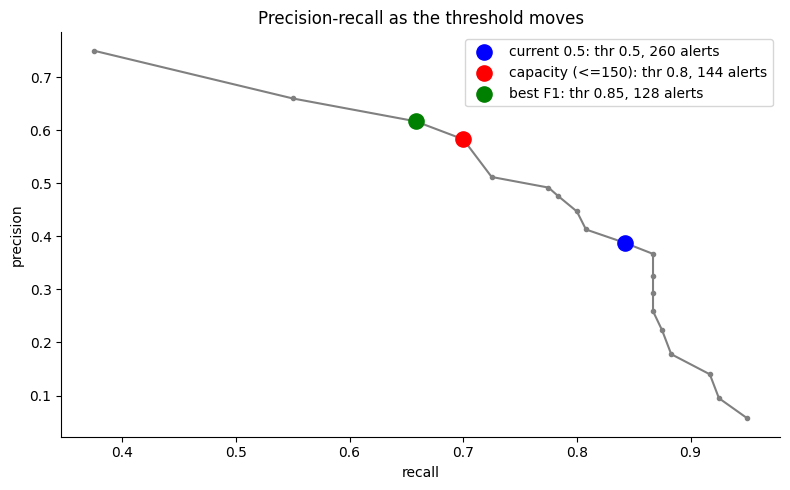

Recommendation: move the threshold from 0.5 (260 alerts) to 0.8 (144 alerts, precision 0.583, recall 0.7); best F1 is at 0.85 (128 alerts, F1 0.637).


In [5]:
rows = []
# TODO 1
for th in np.round(np.arange(0.05, 0.96, 0.05), 2):
    f = tx.detector_score >= th
    tp = int((f & (tx.is_fraud == 1)).sum()); fp = int((f & (tx.is_fraud == 0)).sum()); fn = int((~f & (tx.is_fraud == 1)).sum())
    p = tp / (tp + fp) if tp + fp else np.nan; r = tp / (tp + fn)
    f1 = 2 * p * r / (p + r) if (p == p and p + r > 0) else 0
    rows.append(dict(threshold=th, alerts=int(f.sum()), TP=tp, FP=fp, FN=fn, precision=round(p, 3), recall=round(r, 3), F1=round(f1, 3)))

pr = pd.DataFrame(rows)
display(pr)

# TODO 2
cap = pr[pr.alerts <= 150]
capacity_choice = cap.loc[cap.recall.idxmax()]
best_f1 = pr.loc[pr.F1.idxmax()]
current = pr[pr.threshold == 0.5].iloc[0]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", ms=3, color="grey")
for r_, nm, c in [(current, "current 0.5", "blue"), (capacity_choice, "capacity (<=150)", "red"), (best_f1, "best F1", "green")]:
    ax.scatter(r_.recall, r_.precision, s=120, c=c, label=f"{nm}: thr {r_.threshold}, {int(r_.alerts)} alerts", zorder=5)
ax.set(xlabel="recall", ylabel="precision", title="Precision-recall as the threshold moves"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: move the threshold from 0.5 ({int(current.alerts)} alerts) to {capacity_choice.threshold} "
      f"({int(capacity_choice.alerts)} alerts, precision {capacity_choice.precision}, recall {capacity_choice.recall}); "
      f"best F1 is at {best_f1.threshold} ({int(best_f1.alerts)} alerts, F1 {best_f1.F1}).")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The Head of Fraud Ops should make that call; the model should only show the trade-off. The capacity-constrained choice is **threshold 0.80** (144 alerts ≤ 150, precision 0.583, recall 0.700, F1 0.636) and the best F1 is at **0.85** (128 alerts, precision 0.617, recall 0.658, F1 0.637); they differ by only 5 caught frauds (84 vs 79) against 16 more alerts, and the real cost of a missed fraud versus an investigator hour is business knowledge the model does not have. Visual analytics keeps a human in the loop (Slides 35-37) because the threshold encodes a value judgement, the human can see the precision-recall trade-off, and they remain accountable for it.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3].copy()
fig1 = px.scatter(flagged, x="timestamp", y="amount_inr", log_y=True, color="label",
                  color_discrete_map={"confirmed fraud": "red", "legitimate": "lightgrey"},
                  hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
                  title="Flagged transactions (detector score >= 0.3)")
fig1.update_layout(dragmode="select")
fig1.show()

# TODO 2
sb = tx.groupby(["city", "merchant_category"]).agg(n=("txn_id", "size"), fraud_rate=("is_fraud", "mean")).reset_index()
fig2 = px.sunburst(sb, path=["city", "merchant_category"], values="n", color="fraud_rate", color_continuous_scale="Reds",
                   title="City -> merchant category (size = transactions, colour = fraud rate)")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips show one case at a time, so to get an overview of 400 flagged cases the investigator would have to hover 400 times and remember what each one said, which overloads working memory and never shows the pattern (Slide 23). The views that fix it are the aggregate overviews from this notebook: the **city × day heatmap** (Task 1) and the **sunburst** (city → category coloured by fraud rate), used for overview first, with the tooltips kept for details on demand.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Inside window: 37.4% (40/107) | outside: 1.5% (80/5413) | chi2 = 619.3, p = 1.06e-136
Pune d18-20: 37.4% (40/107)
Pune other days: 1.9% (11/593)
Other cities d18-20: 0.4% (2/457)
Rest: 1.5% (67/4363)


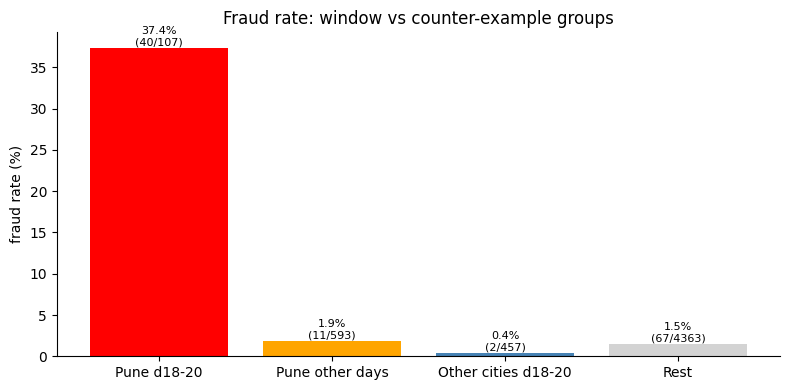

Verdict: SUPPORTED as a localized burst. Pune days 18-20 is far above both counter-examples (same city other days, other cities same days). This shows concentration in one city and time window; it does not by itself prove a single organised ring.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# H: the fraud spike is a localized burst in Pune on days 18-20.
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
ct = pd.crosstab(in_window, tx.is_fraud)
chi2, p, _, _ = chi2_contingency(ct)
rate = lambda m: tx.is_fraud[m].mean()
print(f"Inside window: {rate(in_window):.1%} ({int(tx.is_fraud[in_window].sum())}/{int(in_window.sum())}) | "
      f"outside: {rate(~in_window):.1%} ({int(tx.is_fraud[~in_window].sum())}/{int((~in_window).sum())}) | chi2 = {chi2:.1f}, p = {p:.2e}")

# TODO 3: counter-example searches
same_city_other_days = (tx.city == "Pune") & ~tx.day.between(18, 20)
other_cities_same_days = (tx.city != "Pune") & tx.day.between(18, 20)
rest = (tx.city != "Pune") & ~tx.day.between(18, 20)
groups = {"Pune d18-20": in_window, "Pune other days": same_city_other_days, "Other cities d18-20": other_cities_same_days, "Rest": rest}
for k, m in groups.items(): print(f"{k}: {rate(m):.1%} ({int(tx.is_fraud[m].sum())}/{int(m.sum())})")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(groups), [rate(m) * 100 for m in groups.values()], color=["red", "orange", "steelblue", "lightgrey"])
for i, m in enumerate(groups.values()): ax.text(i, rate(m) * 100 + .3, f"{rate(m):.1%}\n({int(tx.is_fraud[m].sum())}/{int(m.sum())})", ha="center", fontsize=8)
ax.set(ylabel="fraud rate (%)", title="Fraud rate: window vs counter-example groups")
plt.tight_layout(); plt.show()

# TODO 5
print("Verdict: SUPPORTED as a localized burst. Pune days 18-20 is far above both counter-examples (same city other days, other cities same days). "
      "This shows concentration in one city and time window; it does not by itself prove a single organised ring.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

The counter-example that would have killed it is **(b) other cities on the same days**: if the other cities had also shown a high fraud rate on days 18-20, the spike would be date-driven rather than city-specific (for example a system-wide data breach, a detector change or a payday effect), not a ring working in one city. Result: 0.4% (2/457), so the hypothesis survived. Counter-example (a), the same city on other days, would have supported a different alternative, that Pune is simply a permanently high-risk city; it came out at 1.9% (11/593), so that was also ruled out.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month PayKart had 120 confirmed frauds in 5,520 transactions (2.2%), and a third of them (40) were in Pune on days 18-20, a 37.4% fraud rate against 1.5% elsewhere (chi-square p ≈ 1e-136), while the same city on other days (1.9%) and other cities on the same days (0.4%) were normal. I recommend moving the threshold from 0.5 (260 alerts, precision 0.39, recall 0.84) to 0.80, which gives 144 alerts, inside the 150-alert capacity, with precision 0.58 and recall 0.70, and the Head of Fraud Ops should confirm the final value because it is a cost trade-off, not a statistical optimum. The first interactive view to build is the **overview-first city × day heatmap with drill-down**, because it makes bursts like Pune visible at a glance (overview first, then zoom and details on demand), and it can be backed by pre-aggregated data to meet the 0.1 s dynamic-query budget at 50M rows. The feedback loop (Slide 51) is to feed the investigators' confirmed labels back into the detector each month so it is retrained on the cases it got wrong.